# Results

The three signal controllers compared, from a single baseline setting to one
setting at a time, several settings at once, and the lights and queues over
time:

1. the baseline: the three controllers compared
2. mean wait as each setting changes on its own
3. several settings changed at once
4. the effect of each setting on the adaptive controller's advantage
5. the lights and the cars waiting over time
6. the length of the pockets

**Baseline:** arrival rate 0.15 (average chance that a car arrives on each
approach in a step), north–south probability 0.5 (balanced traffic), left-turn
and right-turn probability 0.2 each, no reaction delay. This is busy but below
what any of the controllers can serve.

The data come from `python -m utils.results_sweeps` (`data/fine_sweeps.csv`,
`data/scenarios.csv`, `data/fine_pockets.csv`) and, for one figure, the main
experiment (`data/sweep_results.csv`). Every setting is run with the same seeds
for all three controllers, so they see exactly the same arriving cars. Waits
are in steps (about one second each). Cars that find the entry full are turned
away; the fraction turned away is shown where it matters. Figures are saved to
`figures/` with names starting `results_`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")                          # project folder (this notebook is in notebooks/Results)
sys.path.insert(0, str(ROOT.resolve()))       # so that src/ and utils/ can be imported
FIGURES = ROOT / "figures"

from src.intersection import Intersection
from utils.metrics import run_and_measure
from utils.results_sweeps import BASELINE

CONTROLLERS = ["fixed", "webster", "adaptive"]
LABELS = {"fixed": "Fixed-time (untuned)", "webster": "Fixed-time (Webster)", "adaptive": "Adaptive"}
COLOURS = {"fixed": "C0", "webster": "C2", "adaptive": "C1"}
# code name of each setting -> (column in the data files, axis label)
FACTORS = {
    "demand": ("arrival_rate", "Arrival rate (cars per approach per step)"),
    "ns_probability": ("north_south_probability", "North–south probability"),
    "reaction_delay": ("reaction_delay", "Reaction delay (chance of stalling)"),
    "left_probability": ("left_turn_probability", "Left-turn probability"),
    "right_probability": ("right_turn_probability", "Right-turn probability"),
}


def load(name):
    # One row per run, plus the fraction of arriving cars that were turned away
    # (on average 4 x arrival_rate cars arrive per step, so 400 x arrival_rate per 100 steps).
    df = pd.read_csv(ROOT / "data" / name)
    df["turned_away"] = df["blocked_arrivals"] / (400 * df["arrival_rate"])
    return df


def mean_and_ci(runs, by, value):
    # Mean of `value` over the seeds for each value of `by`, with a 95% interval.
    groups = runs.groupby(by)[value]
    return groups.mean(), 1.96 * groups.std() / np.sqrt(groups.count())


def plot_controllers(ax, runs, by, value="mean_wait", scale=1):
    # One line per controller, with its 95% interval shaded.
    for controller in CONTROLLERS:
        mean, ci = mean_and_ci(runs[runs["controller"] == controller], by, value)
        ax.plot(mean.index, scale * mean, marker="o", markersize=3, color=COLOURS[controller],
                label=LABELS[controller])
        ax.fill_between(mean.index, scale * (mean - ci), scale * (mean + ci), color=COLOURS[controller], alpha=0.2)


def advantage(runs, by, against):
    # Adaptive's percentage reduction in mean wait against another controller,
    # paired run by run (same setting and seed), with a 95% interval over seeds.
    wide = runs.pivot_table(index=[by, "seed"], columns="controller", values="mean_wait")
    reduction = (100 * (wide[against] - wide["adaptive"]) / wide[against]).groupby(level=0)
    return reduction.mean(), 1.96 * reduction.std() / np.sqrt(reduction.count())


def save(fig, name):
    fig.savefig(FIGURES / f"results_{name}.png", dpi=200, bbox_inches="tight")


fine = load("fine_sweeps.csv")
print(f"{len(fine)} runs in the fine sweeps; baseline: {BASELINE}")

2430 runs in the fine sweeps; baseline: {'demand': 0.15, 'ns_probability': 0.5, 'left_probability': 0.2, 'right_probability': 0.2, 'reaction_delay': 0.0}


## 1. Baseline: the three controllers compared

Mean wait at the baseline over 30 seeds (bars: 95% intervals).

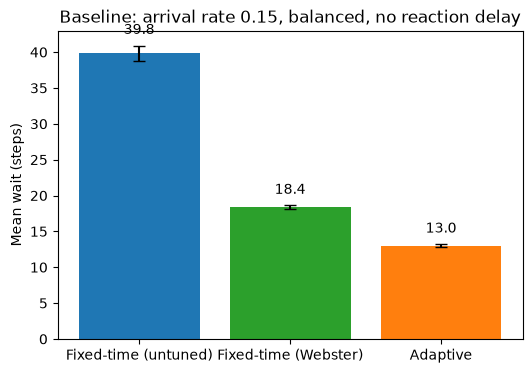

,mean wait (steps),cars served per 100 steps,fraction turned away,light changes per 100 steps
controller,,,,
Fixed-time (untuned),39.819,59.103,0.022,4.350
Fixed-time (Webster),18.354,58.763,0.022,8.700
Adaptive,13.000,58.773,0.022,12.408


In [2]:
base = fine[fine["sweep"] == "baseline"]
summary = base.groupby("controller")[["mean_wait", "throughput", "turned_away", "phase_changes"]].mean()
ci = 1.96 * base.groupby("controller")["mean_wait"].std() / np.sqrt(base.groupby("controller")["mean_wait"].count())

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([LABELS[c] for c in CONTROLLERS], summary.loc[CONTROLLERS, "mean_wait"],
              yerr=ci[CONTROLLERS], capsize=4, color=[COLOURS[c] for c in CONTROLLERS])
ax.bar_label(bars, fmt="%.1f", padding=6)
ax.set_ylabel("Mean wait (steps)")
ax.set_title("Baseline: arrival rate 0.15, balanced, no reaction delay")
save(fig, "baseline")
plt.show()

table = summary.loc[CONTROLLERS].rename(index=LABELS, columns={
    "mean_wait": "mean wait (steps)", "throughput": "cars served per 100 steps",
    "turned_away": "fraction turned away", "phase_changes": "light changes per 100 steps"})
table.round(3)

## 2. Mean wait as each setting changes

Each figure changes one setting and keeps the others at the baseline. Every
point is the mean of 10 seeds; the shaded bands are 95% intervals. The dotted
line marks the baseline value.

### Arrival rate

How busy the intersection is. The bottom panel shows the fraction of arriving
cars turned away because the entry was full: a controller that cannot keep up
fills its approach roads and starts turning cars away.

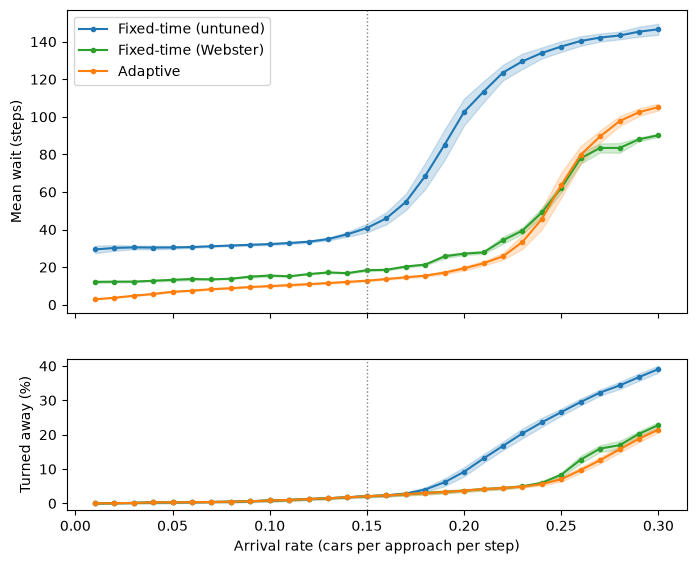

In [3]:
runs = fine[fine["sweep"] == "demand"]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True, height_ratios=[2, 1])
plot_controllers(top, runs, "arrival_rate")
plot_controllers(bottom, runs, "arrival_rate", "turned_away", scale=100)
for ax in (top, bottom):
    ax.axvline(BASELINE["demand"], color="grey", linestyle=":", linewidth=1)
top.set_ylabel("Mean wait (steps)")
bottom.set_ylabel("Turned away (%)")
bottom.set_xlabel(FACTORS["demand"][1])
top.legend()
save(fig, "wait_vs_arrival_rate")
plt.show()

### North–south probability

The chance that an arriving car comes from the north or south: 0.5 is balanced, 1.0 means no traffic from the east or west.

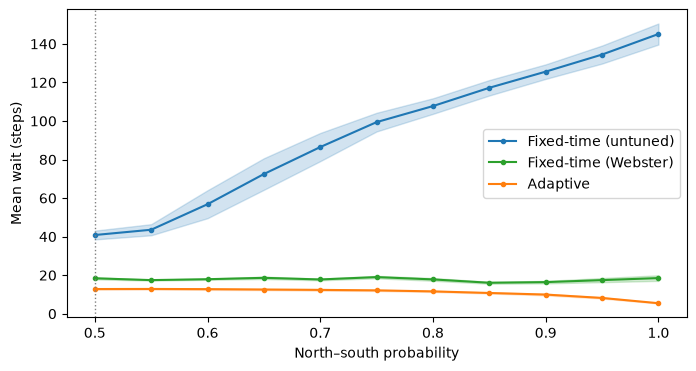

In [4]:
column, label = FACTORS["ns_probability"]
runs = fine[fine["sweep"] == "ns_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["ns_probability"], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "wait_vs_ns_probability")
plt.show()

### Reaction delay

The chance that a car starting from standstill stalls for a step. It slows the start of every queue.

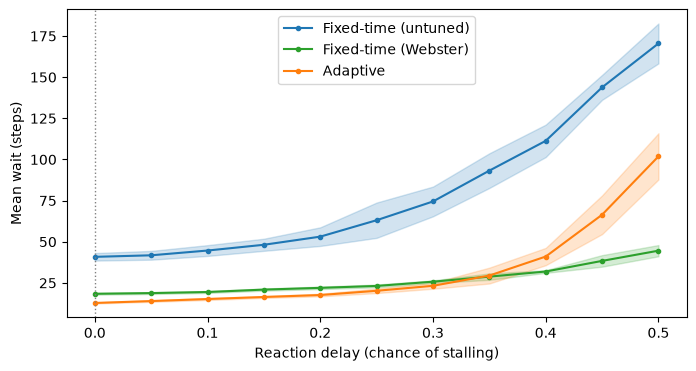

In [5]:
column, label = FACTORS["reaction_delay"]
runs = fine[fine["sweep"] == "reaction_delay"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["reaction_delay"], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "wait_vs_reaction_delay")
plt.show()

### Left-turn probability

The chance that a car turns left (right turns stay at 0.2; the rest go straight). Left turns get green together with straight-on cars.

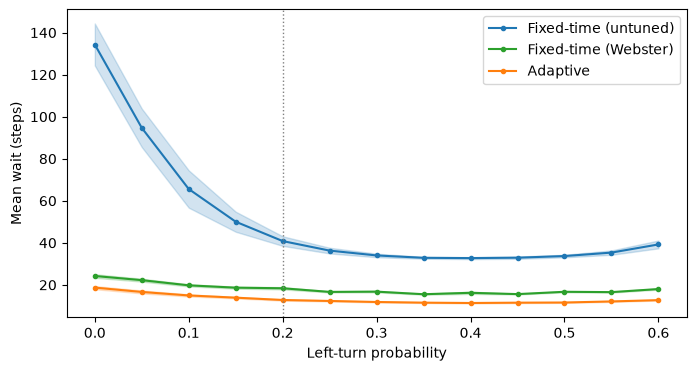

In [6]:
column, label = FACTORS["left_probability"]
runs = fine[fine["sweep"] == "left_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["left_probability"], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "wait_vs_left_probability")
plt.show()

### Right-turn probability

The chance that a car turns right (left turns stay at 0.2; the rest go straight). Right turns cross oncoming traffic, so they get their own phase.

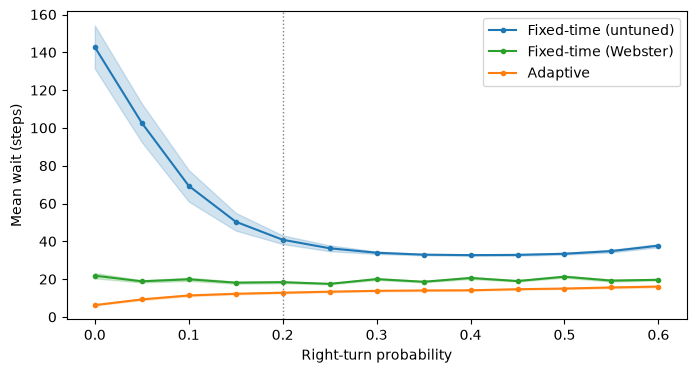

In [7]:
column, label = FACTORS["right_probability"]
runs = fine[fine["sweep"] == "right_probability"]
fig, ax = plt.subplots(figsize=(8, 4))
plot_controllers(ax, runs, column)
ax.axvline(BASELINE["right_probability"], color="grey", linestyle=":", linewidth=1)
ax.set_xlabel(label)
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "wait_vs_right_probability")
plt.show()

## 3. Several settings changed at once

Each scenario changes two or more settings from the baseline (10 seeds each;
bars: 95% intervals).

Settings of each scenario
                                arrival_rate  north_south_probability  \
scenario                                                                
baseline                                0.15                      0.5   
busy, one-sided                         0.18                      0.8   
busy, slow drivers                      0.18                      0.5   
one-sided, many right turns             0.15                      0.8   
slow drivers, many right turns          0.15                      0.5   
light, very one-sided                   0.08                      0.9   
all four harder                         0.18                      0.8   

                                right_turn_probability  reaction_delay  
scenario                                                                
baseline                                           0.2             0.0  
busy, one-sided                                    0.2             0.0  
busy, slow drivers      

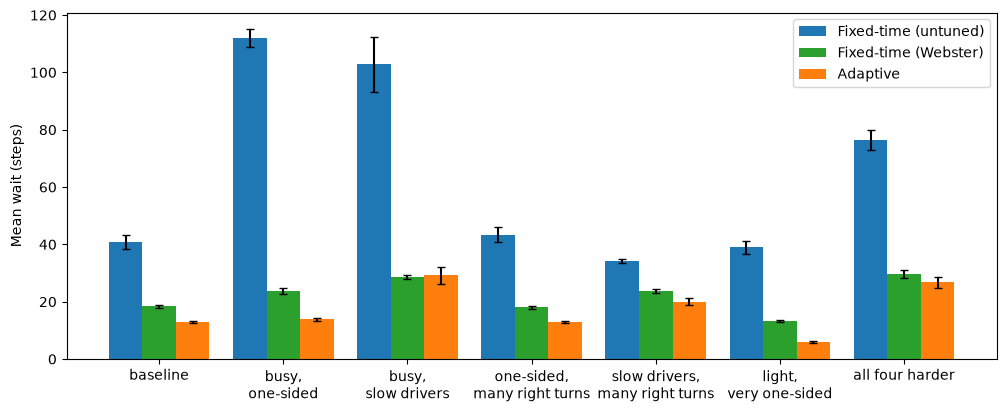

Mean wait (steps)
controller                      Fixed-time (untuned)  Fixed-time (Webster)  \
scenario                                                                     
baseline                                        40.8                  18.4   
busy, one-sided                                112.0                  23.8   
busy, slow drivers                             102.8                  28.6   
one-sided, many right turns                     43.4                  18.0   
slow drivers, many right turns                  34.3                  23.8   
light, very one-sided                           39.0                  13.2   
all four harder                                 76.5                  29.6   

controller                      Adaptive  
scenario                                  
baseline                            12.8  
busy, one-sided                     13.9  
busy, slow drivers                  29.2  
one-sided, many right turns         12.9  
slow drivers, many ri

In [8]:
scenarios = load("scenarios.csv")
order = list(dict.fromkeys(scenarios["scenario"]))
means = scenarios.pivot_table(index="scenario", columns="controller", values="mean_wait").loc[order]
errors = scenarios.groupby(["scenario", "controller"])["mean_wait"].agg(
    lambda w: 1.96 * w.std() / np.sqrt(len(w))).unstack().loc[order]

settings = (scenarios.drop_duplicates("scenario").set_index("scenario").loc[order,
            ["arrival_rate", "north_south_probability", "right_turn_probability", "reaction_delay"]])
print("Settings of each scenario")
print(settings)

fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(order))
width = 0.27
for i, controller in enumerate(CONTROLLERS):
    ax.bar(x + (i - 1) * width, means[controller], width, yerr=errors[controller], capsize=3,
           color=COLOURS[controller], label=LABELS[controller])
ax.set_xticks(x, [name.replace(", ", ",\n") for name in order])
ax.set_ylabel("Mean wait (steps)")
ax.legend()
save(fig, "scenarios")
plt.show()

print("Mean wait (steps)")
print(means[CONTROLLERS].rename(columns=LABELS).round(1))

The main experiment (`data/sweep_results.csv`) changes four settings together
in every combination. Below: adaptive control's reduction in mean wait
against Webster's plan, by arrival rate and north–south probability, for each
reaction delay (averaged over right-turn probabilities and seeds; positive
means adaptive waits less).

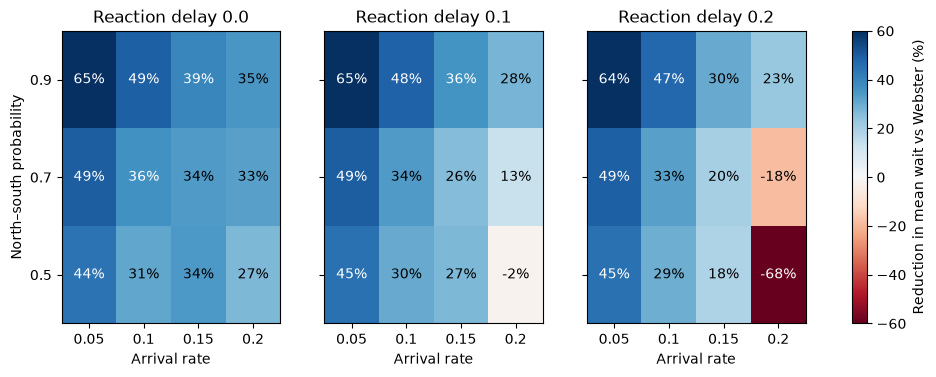

In [9]:
main = load("sweep_results.csv")
wide = main.pivot_table(index=["arrival_rate", "north_south_probability", "right_turn_probability",
                               "reaction_delay", "seed"], columns="controller", values="mean_wait").reset_index()
wide["vs_webster"] = 100 * (wide["webster"] - wide["adaptive"]) / wide["webster"]
delays = sorted(wide["reaction_delay"].unique())
fig, axes = plt.subplots(1, len(delays), figsize=(12, 3.8), sharey=True)
for ax, delay in zip(axes, delays):
    table = wide[wide["reaction_delay"] == delay].pivot_table(
        index="north_south_probability", columns="arrival_rate", values="vs_webster")
    image = ax.imshow(table.values, cmap="RdBu", vmin=-60, vmax=60, origin="lower", aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.values[i, j]
            ax.text(j, i, f"{value:.0f}%", ha="center", va="center", color="white" if abs(value) > 35 else "black")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel("Arrival rate")
    ax.set_title(f"Reaction delay {delay}")
axes[0].set_ylabel("North–south probability")
fig.colorbar(image, ax=axes, label="Reduction in mean wait vs Webster (%)")
plt.show()

## 4. Effect of each setting on the adaptive advantage

Adaptive control's reduction in mean wait against Webster's plan (solid) and
against the untuned plan (dashed), as each setting changes from the baseline
(paired run by run; shaded: 95% intervals). Above zero, adaptive waits less.
Each panel has its own vertical scale.

The zigzag in the turning panels comes from the cellular automaton itself. A
queue starts off one car every two steps, so a green of g steps lets through
about g/2 cars, rounded up: a 9-step green serves as many cars as a 10-step
one. As the turning probability rises, Webster's plan moves one step of green
at a time between phases (for right turns: 11 and 5 steps, then 10 and 6, 9
and 7, ...), alternating between greens that use their time fully and greens
that waste a step, and its waits rise and fall with them.

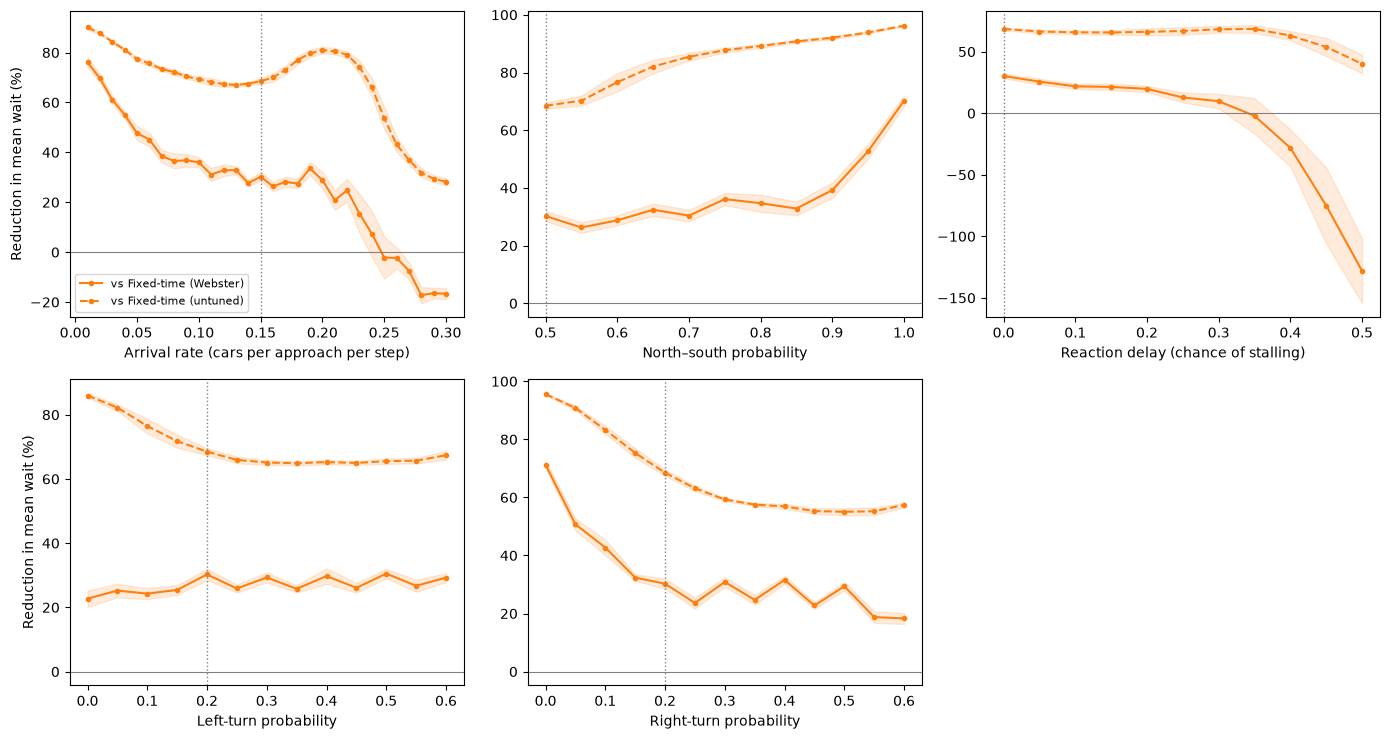

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (factor, (column, label)) in zip(axes.flat, FACTORS.items()):
    runs = fine[fine["sweep"] == factor]
    for against, style in [("webster", "-"), ("fixed", "--")]:
        mean, ci = advantage(runs, column, against)
        ax.plot(mean.index, mean, style, marker="o", markersize=3, color=COLOURS["adaptive"],
                label=f"vs {LABELS[against]}")
        ax.fill_between(mean.index, mean - ci, mean + ci, color=COLOURS["adaptive"], alpha=0.15)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.axvline(BASELINE[factor], color="grey", linestyle=":", linewidth=1)
    ax.set_xlabel(label)
for ax in axes[:, 0]:
    ax.set_ylabel("Reduction in mean wait (%)")
axes[0, 0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.tight_layout()
save(fig, "effect_of_each_setting")
plt.show()

## 5. The lights and the cars waiting

One run of each controller at the baseline (seed 0), recorded step by step:
the cars waiting in the north–south and east–west pockets during 300 steps
of the measured window. Shading shows which direction has a green light;
white is all-red, between two greens.

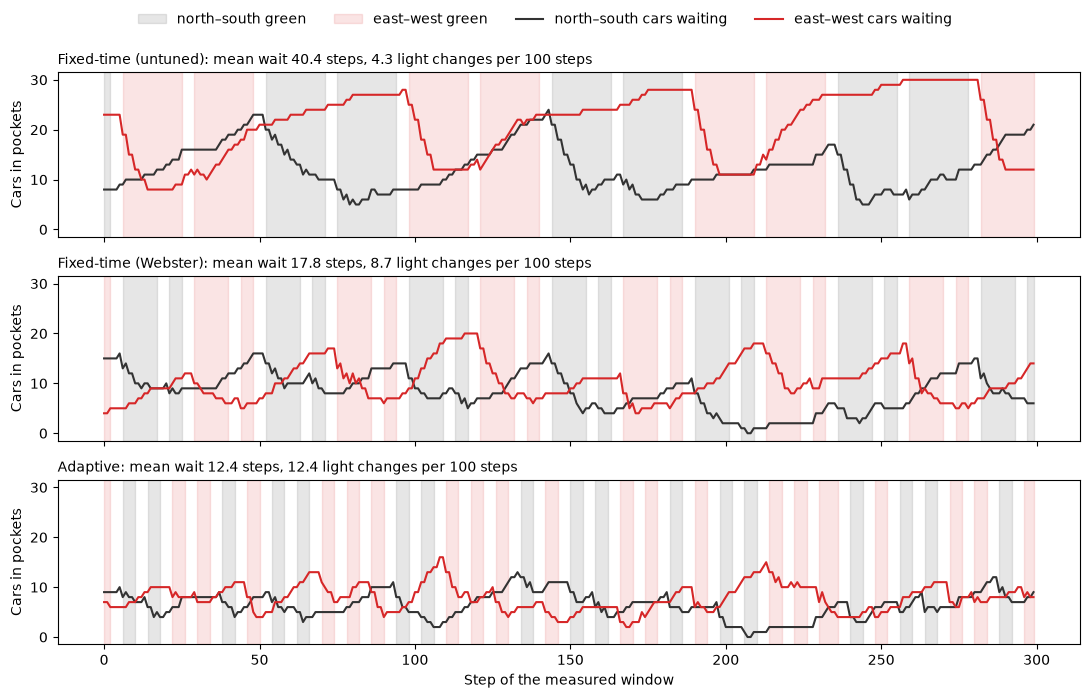

In [11]:
steps = 300
fig, axes = plt.subplots(len(CONTROLLERS), 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, controller in zip(axes, CONTROLLERS):
    run = run_and_measure(Intersection(controller=controller, **BASELINE, seed=0), record=True)
    queues = run["queues"][:steps]          # steps x approaches (N, E, S, W) x moves
    phases = run["phases"][:steps]          # 0, 1 = north-south green; 2, 3 = east-west green; -1 = all-red
    t = np.arange(steps)
    ax.fill_between(t, 0, 1, where=np.isin(phases, [0, 1]), color="0.35", alpha=0.15,
                    transform=ax.get_xaxis_transform(), step="mid", label="north–south green")
    ax.fill_between(t, 0, 1, where=np.isin(phases, [2, 3]), color="C3", alpha=0.12,
                    transform=ax.get_xaxis_transform(), step="mid", label="east–west green")
    ax.plot(t, queues[:, [0, 2]].sum(axis=(1, 2)), color="0.2", label="north–south cars waiting")
    ax.plot(t, queues[:, [1, 3]].sum(axis=(1, 2)), color="C3", label="east–west cars waiting")
    ax.set_title(f"{LABELS[controller]}: mean wait {run['mean_wait']:.1f} steps, "
                 f"{run['phase_changes']:.1f} light changes per 100 steps", loc="left", fontsize=10)
    ax.set_ylabel("Cars in pockets")
axes[-1].set_xlabel("Step of the measured window")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, loc="upper center", frameon=False)
save(fig, "lights_and_queues")
plt.show()

## 6. Pocket lengths

Each approach is a shared lane that splits into three pockets. If a pocket is
full, the car at the split waits, and so does everyone behind it, wherever
they are going (spillback). Left: mean wait against the length of the two
turning pockets, with 20% (solid) and 40% (dashed) of cars turning right.
Middle: how often a car at the split was blocked by its full pocket.
Right: mean wait against the length of the straight pocket (turning pockets
10 cells). The main experiment uses 10 cells for every pocket.

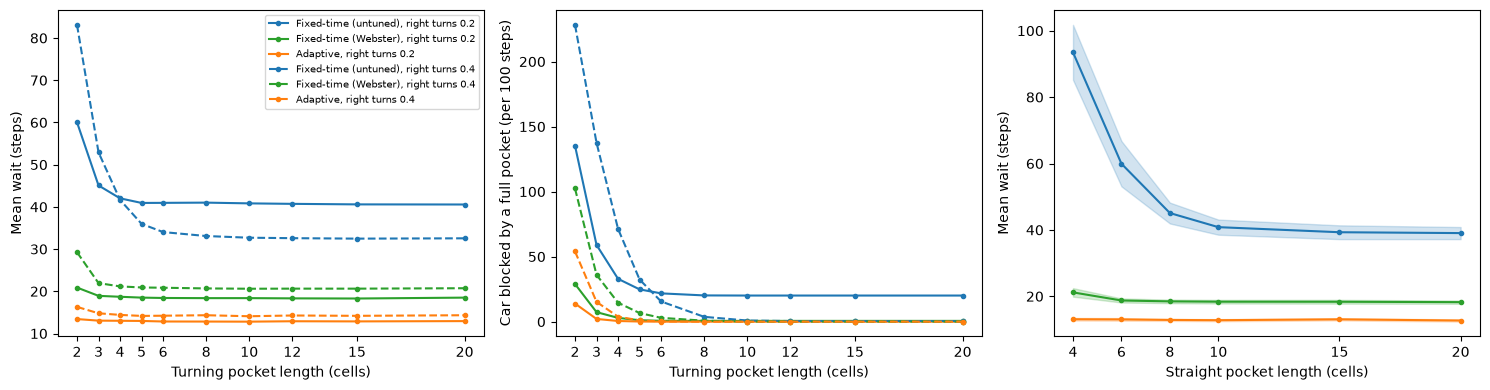

In [12]:
pockets = load("fine_pockets.csv")
turning = pockets[pockets["sweep"] == "turn_pocket_length"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for right, style in [(0.2, "-"), (0.4, "--")]:
    runs = turning[turning["right_turn_probability"] == right]
    for ax, value in zip(axes[:2], ["mean_wait", "full_pocket_blocks"]):
        for controller in CONTROLLERS:
            mean, _ = mean_and_ci(runs[runs["controller"] == controller], "turn_pocket_length", value)
            ax.plot(mean.index, mean, style, marker="o", markersize=3, color=COLOURS[controller],
                    label=f"{LABELS[controller]}, right turns {right}")
plot_controllers(axes[2], pockets[pockets["sweep"] == "pocket_length"], "straight_pocket_length")
axes[0].set_ylabel("Mean wait (steps)")
axes[1].set_ylabel("Car blocked by a full pocket (per 100 steps)")
axes[2].set_ylabel("Mean wait (steps)")
for ax in axes[:2]:
    ax.set_xticks(sorted(turning["turn_pocket_length"].unique()))
    ax.set_xlabel("Turning pocket length (cells)")
axes[2].set_xticks(sorted(pockets.loc[pockets["sweep"] == "pocket_length", "straight_pocket_length"].unique()))
axes[2].set_xlabel("Straight pocket length (cells)")
axes[0].legend(fontsize=7)
fig.tight_layout()
save(fig, "pocket_lengths")
plt.show()